# Section 3: Anomaly Detection for Credit Card Fraud

**What you'll learn**
- See why accuracy is useless when 0.17% of rows are fraud
- Turn PCA reconstruction error into a fraud score
- Grade a score with average precision and the precision-recall curve
- Count how many frauds sit in the top of the list
- Choose the number of components with a sweep
- See why standardising hurts here
- Compare Sparse PCA, ICA, random projection, dictionary learning and Kernel PCA
- Score with Isolation Forest, Local Outlier Factor and ECOD
- Check the chosen detector once on the test set

## Setup
- Slides 1-3

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import (PCA, MiniBatchSparsePCA, FastICA,
                                   MiniBatchDictionaryLearning, KernelPCA)
from sklearn.random_projection import GaussianRandomProjection
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from pyod.models.ecod import ECOD

- 284,807 card transactions from two days in September 2013, a mirror of the ULB dataset
- About 144 MB, downloaded on every run

In [2]:
url = ("https://huggingface.co/datasets/David-Egea/Creditcard-fraud-detection"
       "/resolve/main/creditcard.csv")
df = pd.read_csv(url)
df.shape

(284807, 31)

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

- A model that always answers "not fraud" is right this often

In [5]:
(df["Class"] == 0).mean()

np.float64(0.9982725143693799)

## Preparing the Features
- Slide 4
- `Time` is seconds since the first transaction, not a property of the transaction
- `Class` is the label: kept aside, used only to grade

In [6]:
X = df.drop(columns=["Time", "Class"])
y = df["Class"]
X.var()

V1            3.836489
V2            2.726820
V3            2.299029
V4            2.004684
V5            1.905081
V6            1.774946
V7            1.530401
V8            1.426479
V9            1.206992
V10           1.185594
V11           1.041855
V12           0.998403
V13           0.990571
V14           0.918906
V15           0.837803
V16           0.767819
V17           0.721373
V18           0.702539
V19           0.662662
V20           0.594325
V21           0.539526
V22           0.526643
V23           0.389951
V24           0.366808
V25           0.271731
V26           0.232543
V27           0.162919
V28           0.108955
Amount    62560.069046
dtype: float64

- V1 to V28 are already PCA components, so their variance falls from V1 to V28
- `Amount` is skewed; `log1p` pulls in the long tail

In [7]:
X["Amount"] = np.log1p(X["Amount"])
X["Amount"].var()

np.float64(2.7444838789881607)

- `stratify=y` keeps the same fraud rate in both halves

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, stratify=y)
y_train.sum(), y_test.sum()

(np.int64(330), np.int64(162))

## Reconstruction Error With All Components
- Slides 5-6
- 29 features, 29 components: nothing is thrown away

In [9]:
pca = PCA(n_components=29)
X_back = pca.inverse_transform(pca.fit_transform(X_train))
errors = ((X_train - X_back) ** 2).sum(axis=1)
errors.max()

np.float64(1.4153079504536784e-26)

## Reconstruction Error With 10 Components

In [10]:
pca = PCA(n_components=10)
X_back = pca.inverse_transform(pca.fit_transform(X_train))
errors = ((X_train - X_back) ** 2).sum(axis=1)
errors.groupby(y_train).mean()

Class
0     11.169355
1    312.820103
dtype: float64

## Grading the Score
- Slides 7-9
- Average precision summarises the precision-recall curve in one number
- A random score gets about the fraud rate, 0.0017

In [11]:
average_precision_score(y_train, errors)

0.2666363171572375

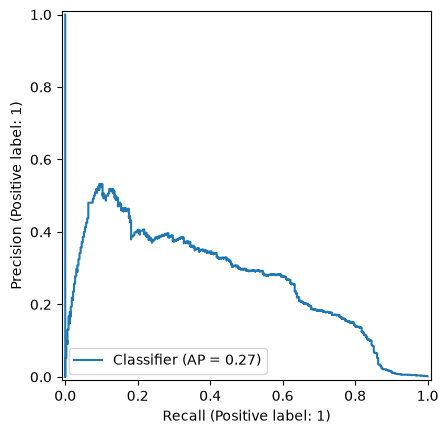

In [12]:
PrecisionRecallDisplay.from_predictions(y_train, errors)

- Review as many transactions as there are frauds: what share of them are fraud?

In [13]:
n = y_train.sum()
y_train[errors.nlargest(n).index].mean()

np.float64(0.3575757575757576)

## Choosing the Number of Components
- Slide 10

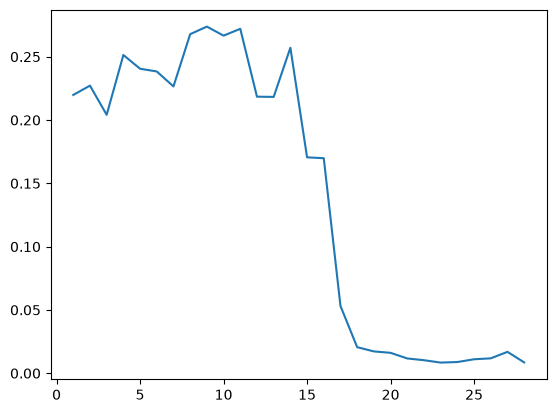

In [14]:
scores = []
for k in range(1, 29):
    pca = PCA(n_components=k)
    X_back = pca.inverse_transform(pca.fit_transform(X_train))
    scores.append(average_precision_score(y_train,
                                          ((X_train - X_back) ** 2).sum(axis=1)))
plt.plot(range(1, 29), scores)

## Standardising First
- Slide 11

In [15]:
X_scaled = StandardScaler().fit_transform(X_train)
pca = PCA(n_components=10)
X_back = pca.inverse_transform(pca.fit_transform(X_scaled))
average_precision_score(y_train, ((X_scaled - X_back) ** 2).sum(axis=1))

0.056379241919961666

## Other Reconstruction Methods
- Slides 12-13
- Every model here has `inverse_transform`, so the same three lines score it
- Random projection needs `compute_inverse_components=True` to go back

In [16]:
models = {
    "PCA": PCA(n_components=10),
    "Sparse PCA": MiniBatchSparsePCA(n_components=10),
    "ICA": FastICA(n_components=10),
    "Random projection": GaussianRandomProjection(n_components=10,
                                                  compute_inverse_components=True),
    "Dictionary learning": MiniBatchDictionaryLearning(n_components=10),
}
results = {}
for name, model in models.items():
    X_back = model.inverse_transform(model.fit_transform(X_train))
    results[name] = average_precision_score(y_train,
                                            ((X_train - X_back) ** 2).sum(axis=1))
pd.Series(results)

PCA                    0.266636
Sparse PCA             0.131169
ICA                    0.266636
Random projection      0.139951
Dictionary learning    0.307141
dtype: float64

## Kernel PCA
- Slide 14
- Fit on 2,000 rows, score the first 50,000: the kernel compares every row with every fitted row
- `fit_inverse_transform=True` learns a way back to the 29 features

In [17]:
kpca = KernelPCA(n_components=10, kernel="rbf", fit_inverse_transform=True)
kpca.fit(X_train[:2000])

,"n_components n_components: int, default=NoneNumber of components. If None, all non-zero components are kept.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'cosine', 'precomputed'} or callable, default='linear'Kernel used for PCA.",'rbf'
,"fit_inverse_transform fit_inverse_transform: bool, default=FalseLearn the inverse transform for non-precomputed kernels(i.e. learn to find the pre-image of a point). This method is basedon [2]_.",True
,"gamma gamma: float, default=NoneKernel coefficient for rbf, poly and sigmoid kernels. Ignored by otherkernels. If ``gamma`` is ``None``, then it is set to ``1/n_features``.",None
,"degree degree: float, default=3Degree for poly kernels. Ignored by other kernels.",3
,"coef0 coef0: float, default=1Independent term in poly and sigmoid kernels.Ignored by other kernels.",1
,"kernel_params kernel_params: dict, default=NoneParameters (keyword arguments) andvalues for kernel passed as callable object.Ignored by other kernels.",None
,"alpha alpha: float, default=1.0Hyperparameter of the ridge regression that learns theinverse transform (when fit_inverse_transform=True).",1.0
,"eigen_solver eigen_solver: {'auto', 'dense', 'arpack', 'randomized'}, default='auto'Select eigensolver to use. If `n_components` is muchless than the number of training samples, randomized (or arpack to asmaller extent) may be more efficient than the dense eigensolver.Randomized SVD is performed according to the method of Halko et al[3]_.auto : the solver is selected by a default policy based on n_samples (the number of training samples) and `n_components`: if the number of components to extract is less than 10 (strict) and the number of samples is more than 200 (strict), the 'arpack' method is enabled. Otherwise the exact full eigenvalue decomposition is computed and optionally truncated afterwards ('dense' method).dense : run exact full eigenvalue decomposition calling the standard LAPACK solver via `scipy.linalg.eigh`, and select the components by postprocessingarpack : run SVD truncated to n_components calling ARPACK solver using `scipy.sparse.linalg.eigsh`. It requires strictly 0 < n_components < n_samplesrandomized : run randomized SVD by the method of Halko et al. [3]_. The current implementation selects eigenvalues based on their module; therefore using this method can lead to unexpected results if the kernel is not positive semi-definite. See also [4]_... versionchanged:: 1.0 `'randomized'` was added.",'auto'
,"tol tol: float, default=0Convergence tolerance for arpack.If 0, optimal value will be chosen by arpack.",0
,"max_iter max_iter: int, default=NoneMaximum number of iterations for arpack.If None, optimal value will be chosen by arpack.",None


In [18]:
X_part, y_part = X_train[:50000], y_train[:50000]
X_back = kpca.inverse_transform(kpca.transform(X_part))
average_precision_score(y_part, ((X_part - X_back) ** 2).sum(axis=1))

0.18564781714659942

## Isolation Forest
- Slides 15-16
- `score_samples` is high for normal rows, so flip the sign

In [19]:
iso = IsolationForest()
iso.fit(X_train)
iso_scores = -iso.score_samples(X_train)
average_precision_score(y_train, iso_scores)

0.1627259504712691

## Local Outlier Factor
- Slides 17-18

In [20]:
lof = LocalOutlierFactor()
lof.fit(X_train)
lof_scores = -lof.negative_outlier_factor_
average_precision_score(y_train, lof_scores)

D:\Corporate Training\2026\unsupervised-learning-in-python\.venv\Lib\site-packages\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


0.0024446181367540516

- Look at each fraud's 20 nearest neighbours: what share are fraud too?

In [21]:
lof20 = LocalOutlierFactor(n_neighbors=21).fit(X_train)
_, neighbours = lof20.kneighbors(X_train[y_train == 1])
y_train.to_numpy()[neighbours[:, 1:]].mean()

D:\Corporate Training\2026\unsupervised-learning-in-python\.venv\Lib\site-packages\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


np.float64(0.6927272727272727)

## ECOD
- Slide 19
- PyOD's ECOD scores each feature by how far into its own tail a value sits
- No settings to tune

In [22]:
ecod = ECOD()
ecod.fit(X_train)
average_precision_score(y_train, ecod.decision_scores_)

0.24542022176975045

## Checking on the Test Set
- Slide 20
- Fit on the training rows only, score the test rows once

In [23]:
pca = PCA(n_components=10)
pca.fit(X_train)
X_back = pca.inverse_transform(pca.transform(X_test))
test_errors = ((X_test - X_back) ** 2).sum(axis=1)
average_precision_score(y_test, test_errors)

0.2009000082757511

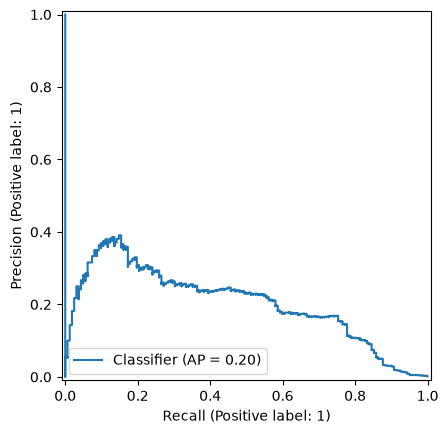

In [24]:
PrecisionRecallDisplay.from_predictions(y_test, test_errors)

In [25]:
average_precision_score(y_test, ecod.decision_function(X_test))

0.1684411642193965

## Lab: A Daily Review Budget
- An analyst can check 100 transactions: how many are fraud?

In [26]:
top = test_errors.nlargest(100)
y_test[top.index].sum()

np.int64(32)

- And how many of the test frauds does that catch?

In [27]:
y_test[top.index].sum() / y_test.sum()

np.float64(0.19753086419753085)

- Try 300 and 1,000 in place of 100

## Wrap-Up
- Slides 21-23